In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [9]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [14]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.utils import to_categorical


In [18]:
df=pd.read_csv('Iris.csv')

In [19]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [21]:
x=df.drop(columns=['Species','Id'],axis=1)
y=df['Species']

In [24]:
encoder=LabelEncoder()
y_integer=encoder.fit_transform(y)
y_integer

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [27]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.33,random_state=42, stratify=y_integer)


In [30]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.fit_transform(x_test)



In [33]:
per=Perceptron(max_iter=1000,random_state=42)
per.fit(x_train_scaled,y_train)

Perceptron(random_state=42)

In [34]:
y_pred=per.predict(x_train_scaled)

In [36]:
accuracy_score(y_train,y_pred)

0.85

In [38]:
from sklearn.metrics import classification_report

In [40]:
 print(classification_report(y_train,y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       0.85      1.00      0.92        34
Iris-versicolor       0.95      0.58      0.72        33
 Iris-virginica       0.80      0.97      0.88        33

       accuracy                           0.85       100
      macro avg       0.87      0.85      0.84       100
   weighted avg       0.87      0.85      0.84       100



In [43]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

y_train_cat = to_categorical(y_train_encoded, num_classes=3)
y_test_cat = to_categorical(y_test_encoded, num_classes=3)

In [46]:
model=Sequential([
    Dense(16,input_dim=4,activation='relu'),
    Dense(8,activation='relu'),
    Dense(3,activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [47]:
model.compile(optimizer='adam',loss='categorical_crossentropy', metrics=['accuracy'])

In [49]:
history=model.fit(x_train_scaled,y_train_cat,epochs=100,batch_size=8,validation_split=0.2,verbose=1)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step - accuracy: 0.3000 - loss: 1.0962 - val_accuracy: 0.4000 - val_loss: 1.0524
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3875 - loss: 1.0252 - val_accuracy: 0.8000 - val_loss: 0.9866
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6500 - loss: 0.9512 - val_accuracy: 0.7000 - val_loss: 0.9206
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6875 - loss: 0.8805 - val_accuracy: 0.6000 - val_loss: 0.8574
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7000 - loss: 0.8128 - val_accuracy: 0.6000 - val_loss: 0.8017
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7125 - loss: 0.7571 - val_accuracy: 0.6000 - val_loss: 0.7522
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7000 - loss: 0.7062 - val_accuracy: 0.6000 - val_loss: 0.7129
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7125 - loss: 0.6637 - val_accuracy: 0.5500 -

In [51]:
losss,acc=model.evaluate(x_test_scaled,y_test_cat,verbose=1)
print(acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9000 - loss: 0.1826
0.8999999761581421


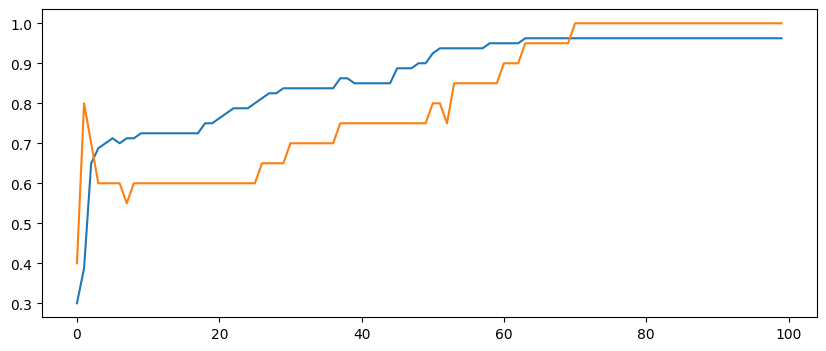

In [53]:
plt.figure(figsize=(10,4))
plt.plot(history.history['accuracy'],label="train Acc")
plt.plot(history.history['val_accuracy'],label="val Acc")